In [66]:
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

#k_means
def Train(nb_classe, X):
    indices = np.random.choice(len(X), nb_classe, replace=False)
    Y = X[indices].copy()
    dic = {i: [] for i in range(nb_classe)}
    for it in range(10000000000000):  # condition d'arret d'urgence
        for x in X:
            dist = float("Inf")
            for i in range(nb_classe):
                sample_dist = np.linalg.norm(x-Y[i])#distance euclidienne
                if sample_dist < dist :
                    dist = sample_dist
                    cluster_index = i
            dic[cluster_index].append(x)
        # barycentre
        Y_updt = np.copy(Y)
        for i in range(len(Y)):
            Y_updt[i] = np.mean(dic[i], axis=0)
        if np.linalg.norm(Y - Y_updt) < 1e-5:
            print("has converged")
            break;
        else:
            Y = Y_updt
            dic = {i: [] for i in range(nb_classe)}
    return Y

def Evaluate(x, clusters):
    dist_min = float("Inf")
    cluster = -1
    for index, y in enumerate(clusters) :
        dist = np.linalg.norm(y-x)
        if dist<dist_min :
            dist_min = dist
            cluster = index
    return cluster

def PrepareDataForClassification(trainingDataFolderPath, testDataFolderPath):
    return (PrepareFolderForClassification(trainingDataFolderPath), PrepareFolderForClassification(testDataFolderPath))

def PrepareFolderForClassification(folderPath):
    dataFolder = Path(folderPath)
    dataSet = []
    for img_path in sorted(dataFolder.glob("*png")):
        data = PrepareData(img_path)
        dataSet.append(data)
    return np.array(dataSet);

def PrepareData(file):
    img = np.array(Image.open(file))
    hist_r = np.histogram(img[:, :, 0].ravel(), bins=256, range=(0, 256), density = True)[0]
    hist_g = np.histogram(img[:, :, 1].ravel(), bins=256, range=(0, 256), density = True)[0]
    hist_b = np.histogram(img[:, :, 2].ravel(), bins=256, range=(0, 256), density = True)[0]
    data = np.concatenate([hist_r, hist_g, hist_b])
    return data

def PlotClassHisto(class_name, clusters):
    classes = ["A", "B", "C", "D", "E", "F", "G", "H"]
    histo = {}
    for img_path in sorted(Path("Data/Classification/Test").glob(class_name + "_*.png")):
        group = classes[Evaluate(PrepareData(img_path), clusters)]
        if group in histo:
            histo[group] += 1
        else :
            histo[group] = 1

    plt.bar(histo.keys(), histo.values())
    for x, y in histo.items():
        plt.text(x, y + 0.1, str(y), ha="center", va="bottom")

    plt.xlabel("Cluster")
    plt.ylabel("Nombre d'images")
    plt.title("Répartition des images de la classe "+class_name+" par cluster")
    plt.xticks(list(histo.keys()))
    plt.show()

In [67]:
trainingData, testData = PrepareDataForClassification("Data/Classification/Training", "Data/Classification/Test")
clusters = Train(8, trainingData)
print(clusters)

has converged
[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.00015955 0.00259937 0.00630713 ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.02326196 0.0132041  0.01406177 ... 0.         0.         0.        ]]


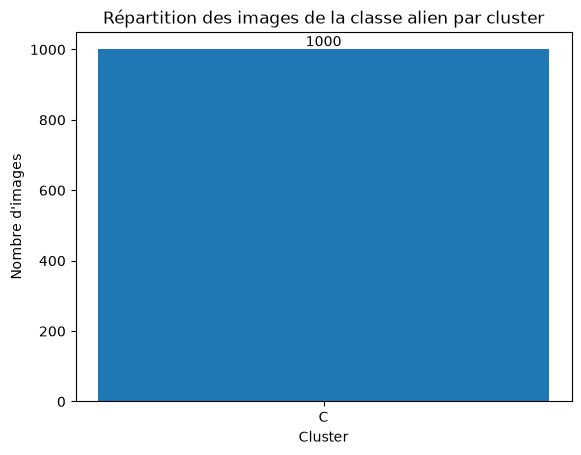

In [68]:
PlotClassHisto("alien", clusters)

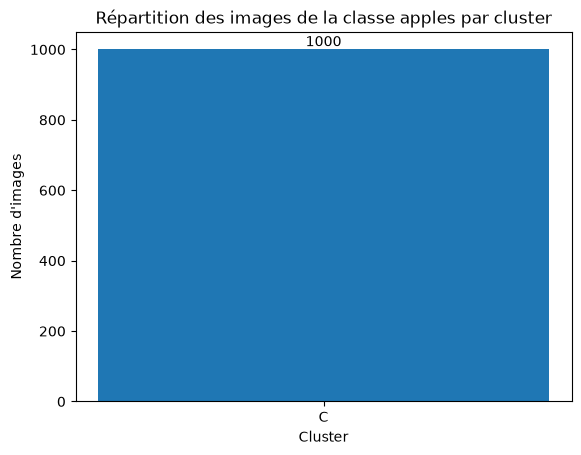

In [69]:
PlotClassHisto("apples", clusters)

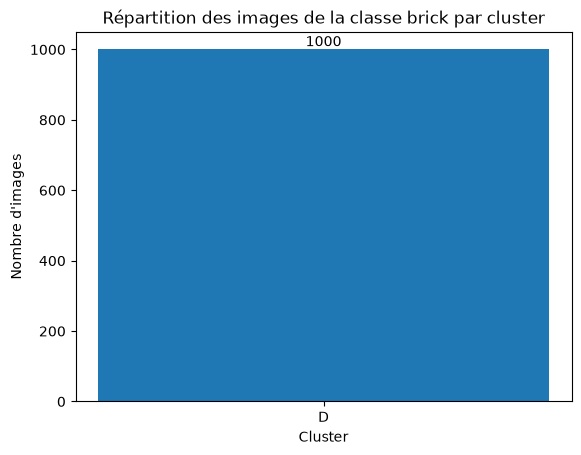

In [70]:
PlotClassHisto("brick", clusters)

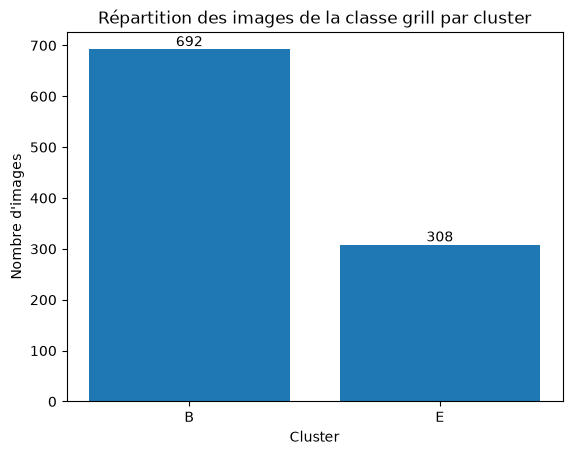

In [71]:
PlotClassHisto("grill", clusters)

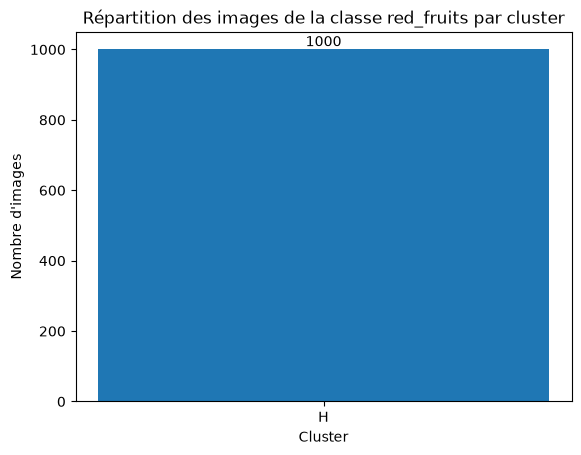

In [72]:
PlotClassHisto("red_fruits", clusters)

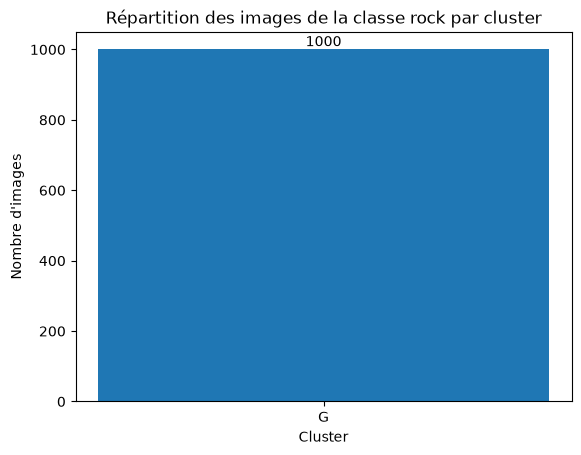

In [73]:
PlotClassHisto("rock", clusters)

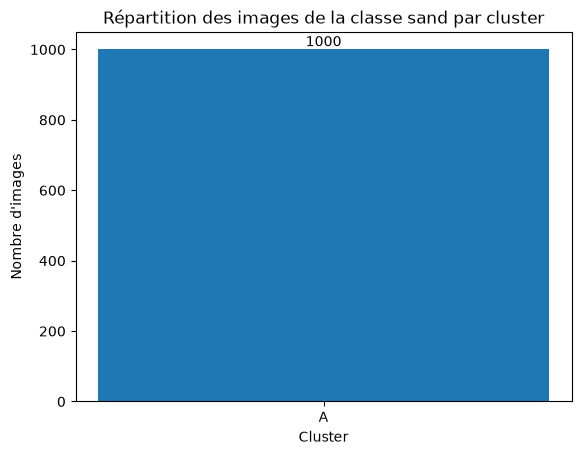

In [74]:
PlotClassHisto("sand", clusters)

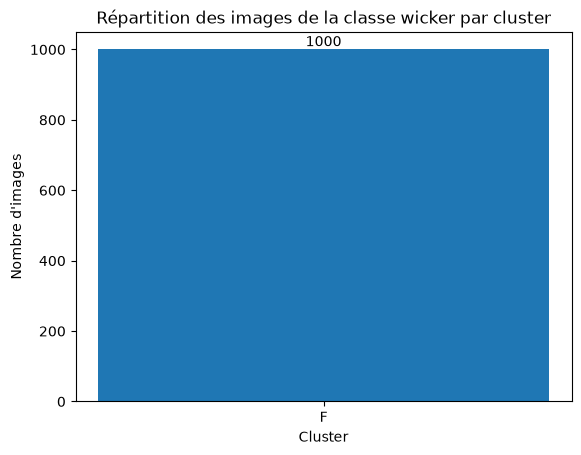

In [75]:
PlotClassHisto("wicker", clusters)

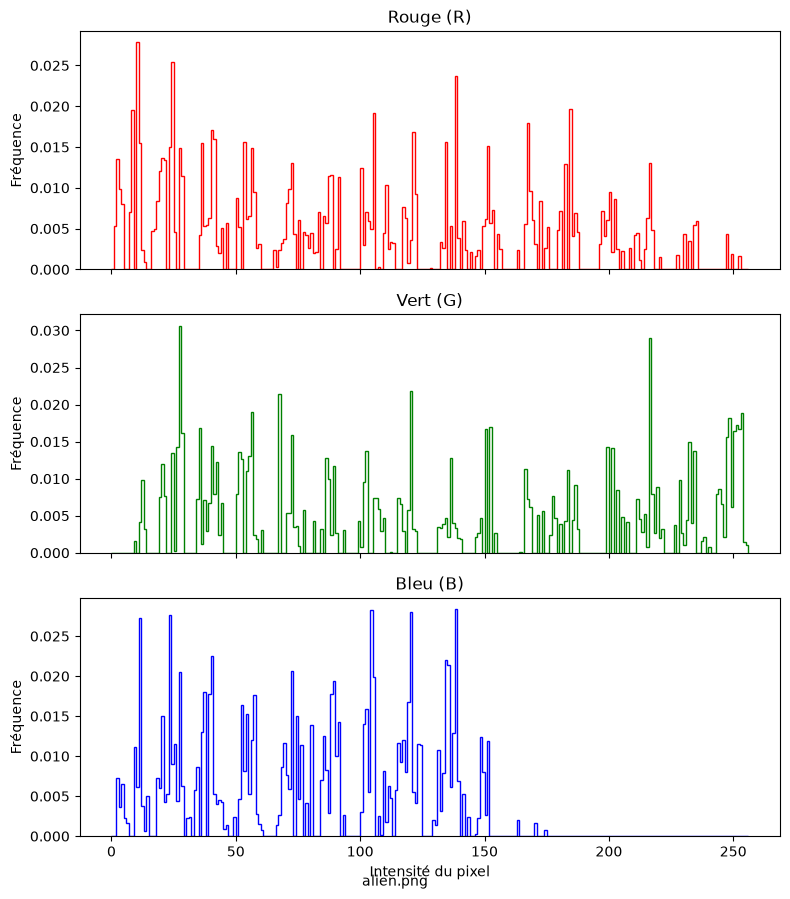

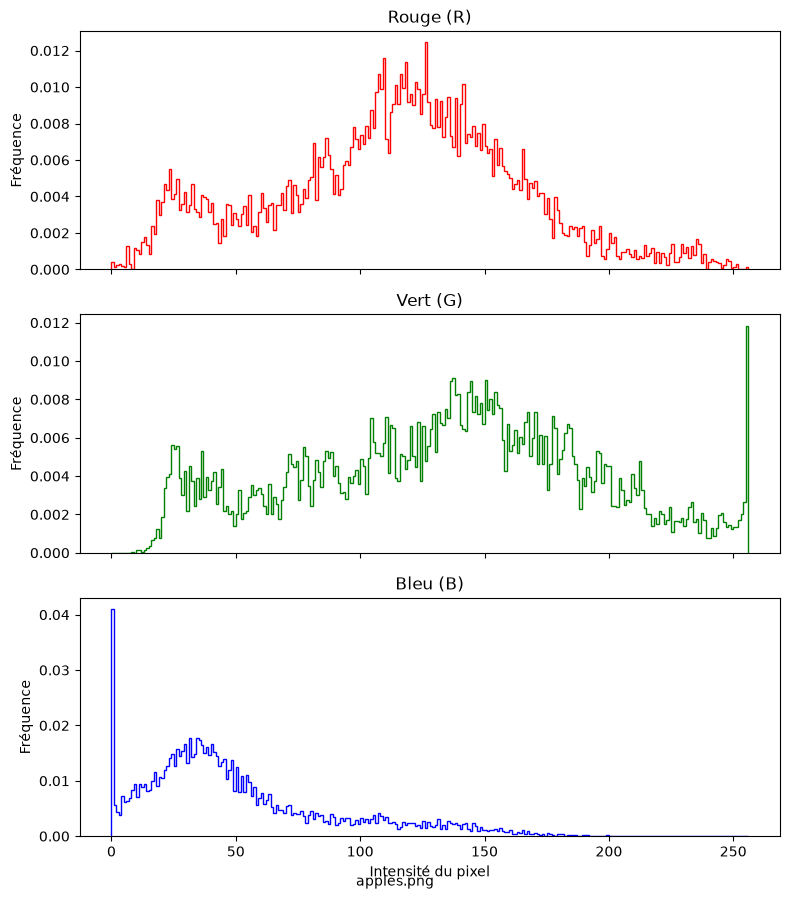

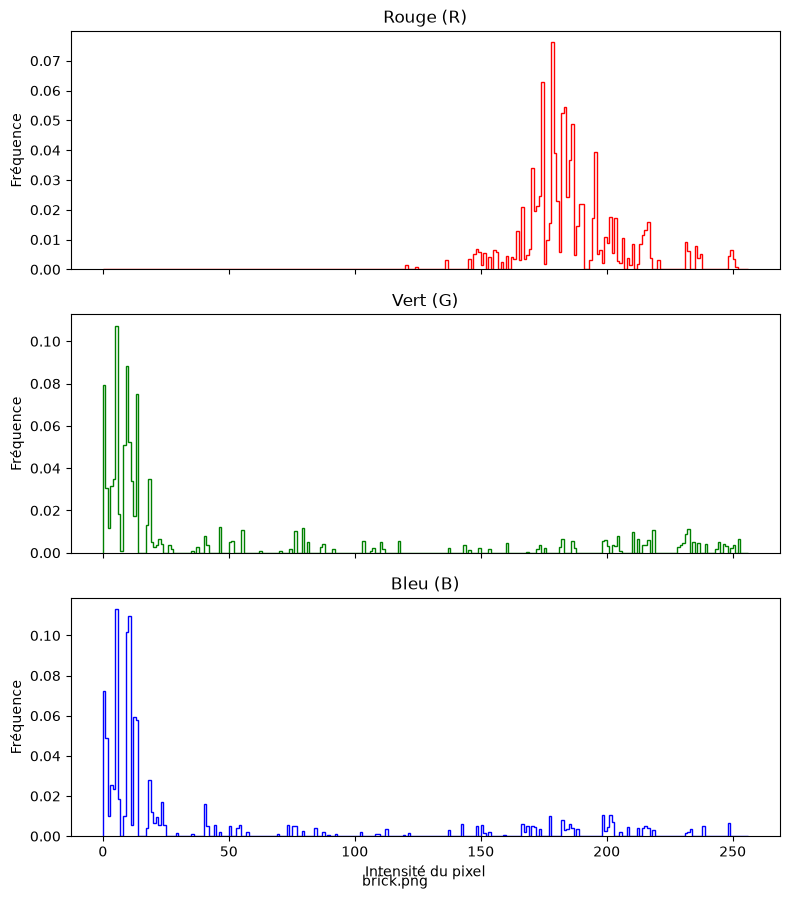

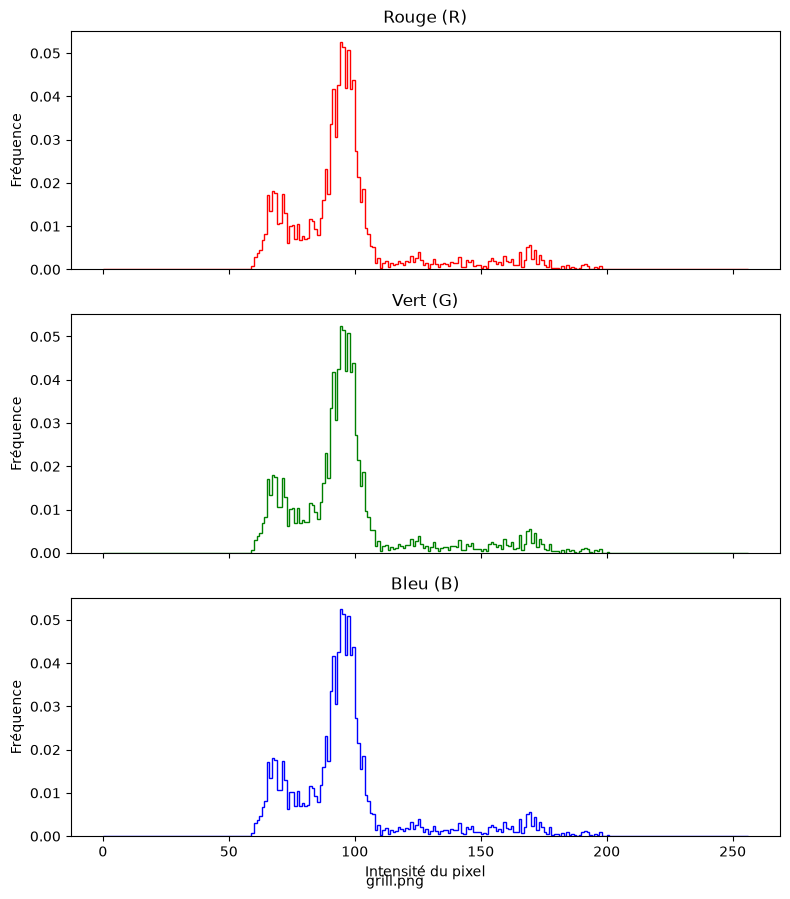

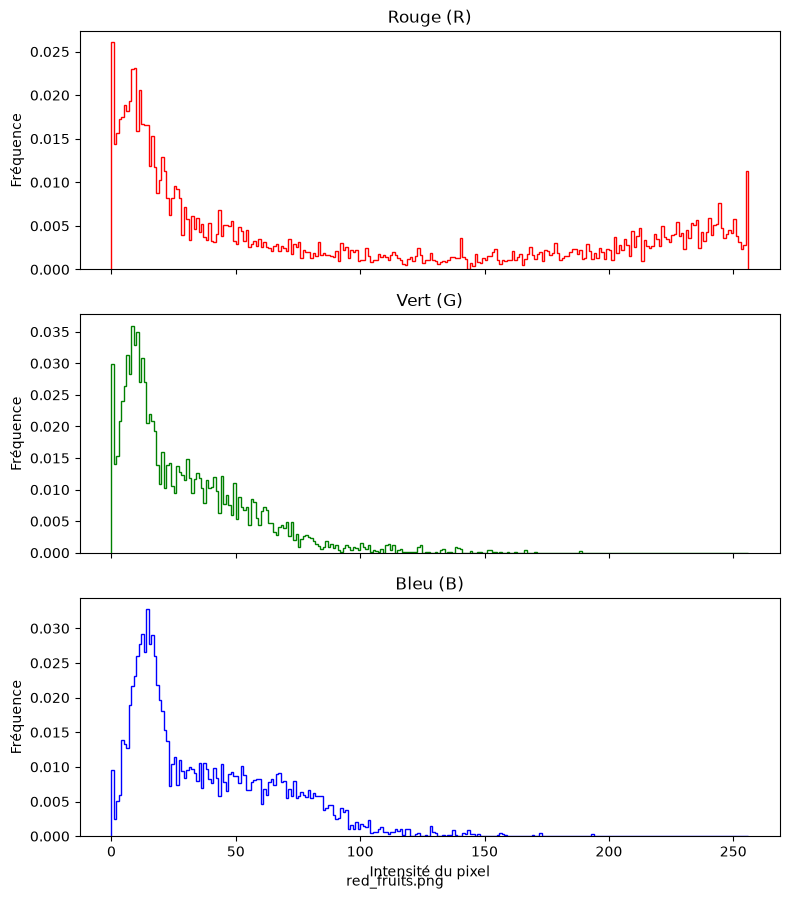

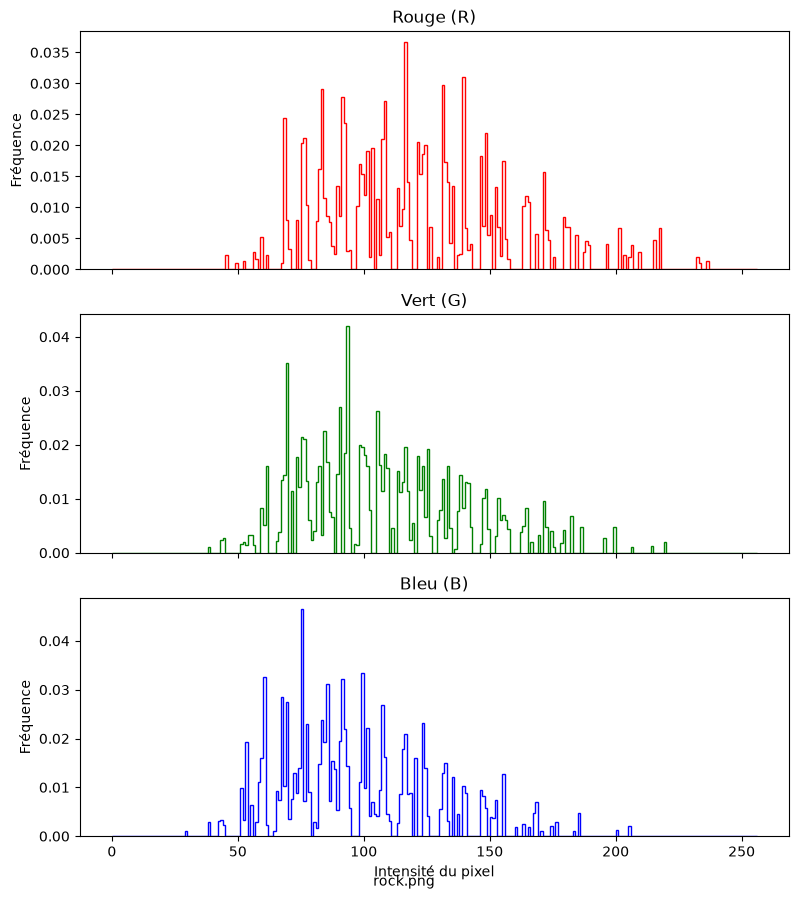

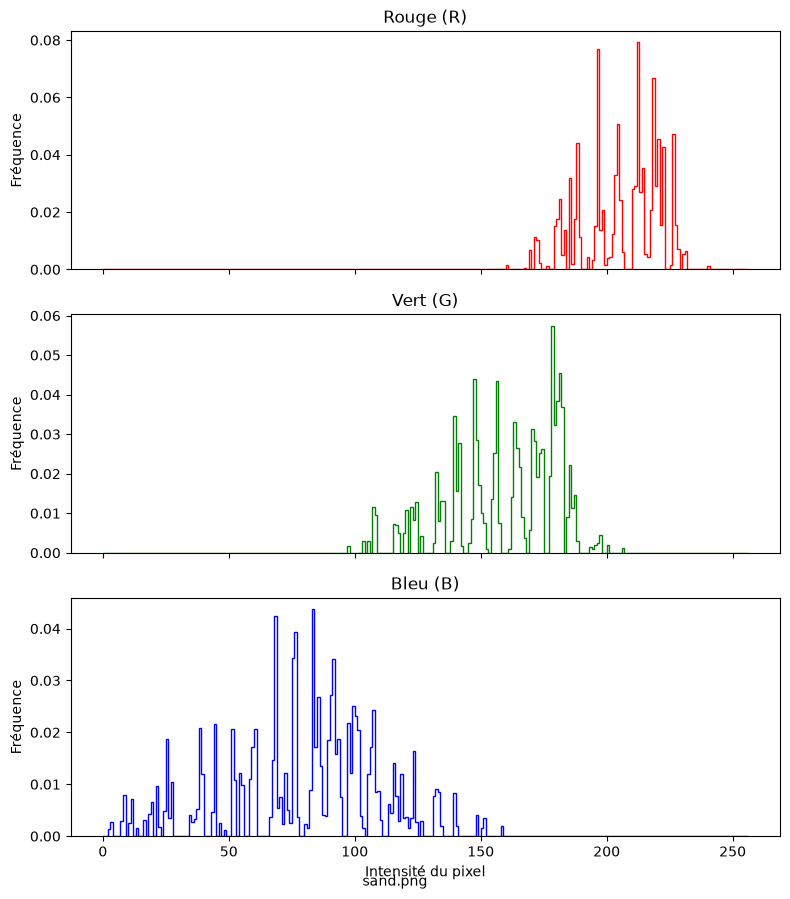

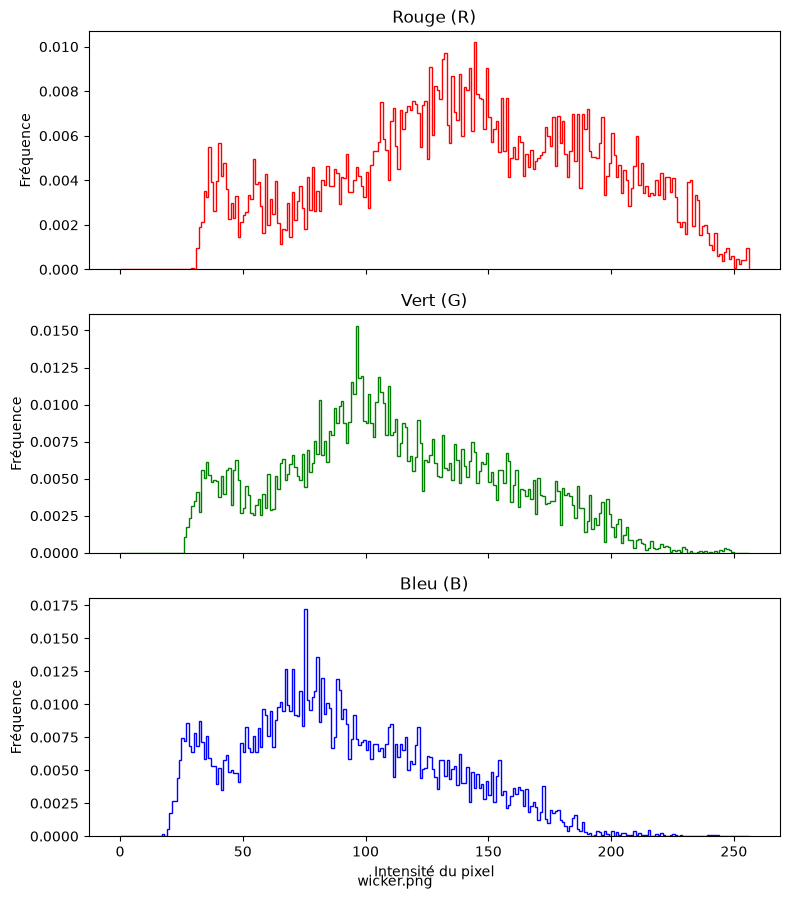

In [78]:
def PlotImageHisto(src):
    img = np.array(Image.open(src).convert("RGB"))

    fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
    canaux = [0, 1, 2]
    couleurs = ["red", "green", "blue"]
    noms = ["Rouge (R)", "Vert (G)", "Bleu (B)"]

    for ax, canal, couleur, nom in zip(axes, canaux, couleurs, noms):
        ax.hist(
            img[:, :, canal].ravel(),
            bins=256,
            range=(0, 256),
            color=couleur,
            histtype="step",
            density=True
        )
        ax.set_title(nom)
        ax.set_ylabel("Fréquence")

    axes[-1].set_xlabel("Intensité du pixel")
    fig.text(0.5, 0.01, Path(src).name, ha="center")
    plt.tight_layout()
    plt.show()

PlotImageHisto("Data/Generated/alien.png")
PlotImageHisto("Data/Generated/apples.png")
PlotImageHisto("Data/Generated/brick.png")
PlotImageHisto("Data/Generated/grill.png")
PlotImageHisto("Data/Generated/red_fruits.png")
PlotImageHisto("Data/Generated/rock.png")
PlotImageHisto("Data/Generated/sand.png")
PlotImageHisto("Data/Generated/wicker.png")